# SPIDER – Unary IND Discovery on Sakila
Evaluated against declared foreign keys (ground truth) with accuracy, precision, recall, F1.

In [1]:
import sqlite3
import time
import heapq
import urllib.request
import pandas as pd
from itertools import permutations

In [2]:
url = "https://sq.io/testdata/sakila.db"
urllib.request.urlretrieve(url, "sakila.db")
print("Database Downloaded Successfully !!")

Database Downloaded Successfully !!


In [3]:
con = sqlite3.connect("sakila.db")

tables = [r[0] for r in con.execute(
    "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%'")]
print(len(tables), "tables:")
print(tables)

16 tables:
['actor', 'country', 'city', 'address', 'language', 'category', 'customer', 'film', 'film_actor', 'film_category', 'film_text', 'inventory', 'staff', 'store', 'payment', 'rental']


In [4]:
pd.read_sql('SELECT * FROM "actor" LIMIT 10', con)

,actor_id,first_name,last_name,last_update
0,1,PENELOPE,GUINESS,2020-02-15 06:59:28
1,2,NICK,WAHLBERG,2020-02-15 06:59:28
2,3,ED,CHASE,2020-02-15 06:59:28
3,4,JENNIFER,DAVIS,2020-02-15 06:59:28
4,5,JOHNNY,LOLLOBRIGIDA,2020-02-15 06:59:28
5,6,BETTE,NICHOLSON,2020-02-15 06:59:28
6,7,GRACE,MOSTEL,2020-02-15 06:59:28
7,8,MATTHEW,JOHANSSON,2020-02-15 06:59:28
8,9,JOE,SWANK,2020-02-15 06:59:28
9,10,CHRISTIAN,GABLE,2020-02-15 06:59:28


In [5]:
def norm(v):
    # 1.0 and 1 are the same value
    if isinstance(v, float) and v.is_integer():
        v = int(v)
    return str(v)

cols = {}   # (table, column) -> set of values
empty_cols = []
for t in tables:
    df = pd.read_sql(f'SELECT * FROM "{t}"', con)
    for c in df.columns:
        vals = set(map(norm, df[c].dropna()))
        if vals:
            cols[(t, c)] = vals
        else:
            empty_cols.append((t, c))   # all-NULL / empty column, cannot take part in any IND

print(len(cols), "Columns Loaded Successfully")
print(len(empty_cols), "empty columns skipped:", empty_cols)

83 Columns Loaded Successfully
6 empty columns skipped: [('address', 'address2'), ('film', 'original_language_id'), ('film_text', 'film_id'), ('film_text', 'title'), ('film_text', 'description'), ('staff', 'picture')]


## SPIDER
Sort each column's distinct values, merge all columns with a min-heap, and for every value intersect the candidate set of each column that contains it with the group of columns that share that value.

In [6]:
def spider(cols):
    attrs   = list(cols)
    sorted_ = {a: sorted(cols[a]) for a in attrs}       # 1. sort distinct values per column
    all_ids = frozenset(range(len(attrs)))
    refs    = {i: set(all_ids - {i}) for i in all_ids}   # refs[A] = candidates B with A <= B
    refd    = {i: set(all_ids - {i}) for i in all_ids}   # refd[B] = columns A still treating B as candidate
    pos     = {i: 0 for i in all_ids}

    heap = [(sorted_[attrs[i]][0], i) for i in all_ids]  # 2. min-heap over first values
    heapq.heapify(heap)

    while heap:
        value, i = heapq.heappop(heap)
        group = {i}
        while heap and heap[0][0] == value:              # 3. all columns containing this value
            group.add(heapq.heappop(heap)[1])

        for a in group:                                  # 4. A can only be included in columns of the group
            removed = refs[a] - group
            refs[a] -= removed
            for b in removed:
                refd[b].discard(a)

        for a in group:                                  # 5. advance cursors, prune finished columns
            pos[a] += 1
            if pos[a] < len(sorted_[attrs[a]]) and (refs[a] or refd[a]):
                heapq.heappush(heap, (sorted_[attrs[a]][pos[a]], a))

    return {(attrs[a], attrs[b]) for a in refs for b in refs[a]
            if attrs[a][0] != attrs[b][0]}              # different tables only (same as baseline)

t0 = time.perf_counter()
found = spider(cols)
t_spider = time.perf_counter() - t0
print(len(found), "INDs Found by SPIDER", f"({t_spider*1000:.1f} ms)")

596 INDs Found by SPIDER (861.3 ms)


In [7]:
# Finding Ground Truth
def primary_key(t):
    return [r[1] for r in con.execute(f'PRAGMA table_info("{t}")') if r[5] >= 1]

gt = set()
for t in tables:
    for r in con.execute(f'PRAGMA foreign_key_list("{t}")'):
        ref_table, from_col, to_col = r[2], r[3], r[4]
        if to_col is None:                      # implicit reference to PK
            pk = primary_key(ref_table)
            to_col = pk[0] if pk else None
        if to_col and ref_table != t:
            gt.add(((t, from_col), (ref_table, to_col)))

print(len(gt), "declared FKs")
sorted(gt)

22 declared FKs


[(('address', 'city_id'), ('city', 'city_id')),
 (('city', 'country_id'), ('country', 'country_id')),
 (('customer', 'address_id'), ('address', 'address_id')),
 (('customer', 'store_id'), ('store', 'store_id')),
 (('film', 'language_id'), ('language', 'language_id')),
 (('film', 'original_language_id'), ('language', 'language_id')),
 (('film_actor', 'actor_id'), ('actor', 'actor_id')),
 (('film_actor', 'film_id'), ('film', 'film_id')),
 (('film_category', 'category_id'), ('category', 'category_id')),
 (('film_category', 'film_id'), ('film', 'film_id')),
 (('inventory', 'film_id'), ('film', 'film_id')),
 (('inventory', 'store_id'), ('store', 'store_id')),
 (('payment', 'customer_id'), ('customer', 'customer_id')),
 (('payment', 'rental_id'), ('rental', 'rental_id')),
 (('payment', 'staff_id'), ('staff', 'staff_id')),
 (('rental', 'customer_id'), ('customer', 'customer_id')),
 (('rental', 'inventory_id'), ('inventory', 'inventory_id')),
 (('rental', 'staff_id'), ('staff', 'staff_id')),
 

## Evaluation
Candidate space = every ordered pair of (column A, column B) from different tables.  
TP = IND found and is a declared FK, FP = IND found but not an FK, FN = FK not found, TN = everything else.

In [12]:
# Candidate space: all ordered cross-table column pairs
N = sum(1 for a, b in permutations(cols, 2) if a[0] != b[0])

tp = found & gt
fp = found - gt
fn = gt - found
TP, FP, FN = len(tp), len(fp), len(fn)
TN = N - TP - FP - FN

precision   = TP / (TP + FP) if TP + FP else 0
recall      = TP / (TP + FN) if TP + FN else 0
f1          = 2 * precision * recall / (precision + recall) if precision + recall else 0
accuracy    = (TP + TN) / N
specificity = TN / (TN + FP) if TN + FP else 0

print("Candidate pairs     :", N)
print("Declared FKs        :", len(gt))
print("INDs found (SPIDER) :", len(found))
print()
print("N: ",N)
print("TP :", TP, "| FP :", FP, "| FN :", FN, "| TN :", TN)
print()
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"Specificity : {specificity:.4f}")
print()
print("Missed FKs  :", sorted(fn))

Candidate pairs     : 6308
Declared FKs        : 22
INDs found (SPIDER) : 596

N:  6308
TP : 21 | FP : 575 | FN : 1 | TN : 5711

Accuracy    : 0.9087
Precision   : 0.0352
Recall      : 0.9545
F1-score    : 0.0680
Specificity : 0.9085

Missed FKs  : [(('film', 'original_language_id'), ('language', 'language_id'))]


               Predicted FK (IND found)  Predicted Not-FK
Actual FK                            21                 1
Actual Not-FK                       575              5711


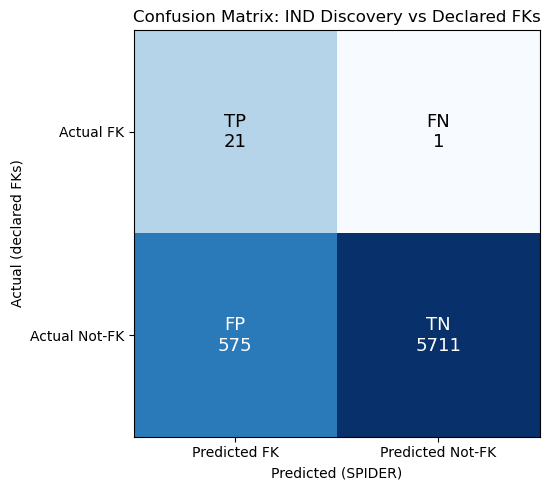

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Rows = actual, columns = predicted
cm = np.array([[TP, FN],
               [FP, TN]])

# 1) Text / table version
cm_df = pd.DataFrame(
    cm,
    index=["Actual FK", "Actual Not-FK"],
    columns=["Predicted FK (IND found)", "Predicted Not-FK"]
)
print(cm_df)

# 2) Heatmap version
fig, ax = plt.subplots(figsize=(6, 5))
# log color scale, because TN is huge compared to TP/FN and would hide everything else
ax.imshow(np.log10(cm + 1), cmap="Blues")

labels = [["TP", "FN"], ["FP", "TN"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}",
                ha="center", va="center", fontsize=13,
                color="white" if np.log10(cm[i, j] + 1) > np.log10(cm.max() + 1) / 2 else "black")

ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted FK", "Predicted Not-FK"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual FK", "Actual Not-FK"])
ax.set_xlabel("Predicted (SPIDER)")
ax.set_ylabel("Actual (declared FKs)")
ax.set_title("Confusion Matrix: IND Discovery vs Declared FKs")
plt.tight_layout()
plt.show()

In [ ]:
# Why were the FKs missed? (empty/all-NULL column or real violation)
for a, b in sorted(fn):
    if a in empty_cols or b in empty_cols:
        print(a, "->", b, ": column is empty/all NULL, so no IND can be found")
    else:
        print(a, "->", b, ": real inclusion violation, values missing:", sorted(cols[a] - cols[b])[:10])

In [ ]:
# Sanity check against the brute-force baseline
def discover_inds_baseline(cols):
    found = set()
    for a, b in permutations(cols, 2):
        if a[0] != b[0] and cols[a] <= cols[b]:
            found.add((a, b))
    return found

t0 = time.perf_counter()
baseline = discover_inds_baseline(cols)
t_base = time.perf_counter() - t0

print("Baseline INDs :", len(baseline), f"({t_base*1000:.1f} ms)")
print("SPIDER INDs   :", len(found),    f"({t_spider*1000:.1f} ms)")
print("SPIDER == Baseline :", found == baseline)

In [ ]:
# Some false positives (valid INDs that are not declared FKs)
for a, b in sorted(fp)[:20]:
    print(f"{a[0]}.{a[1]}  <=  {b[0]}.{b[1]}")